# ENVIRONMENT SETUP, DATASET DOWNLOAD, AND MODEL CONFIGURATIONS
**Project**: Counterfeit Medicine Detection

**Models**: EfficientNet-B0 (primary) and MobileNetV2 (edge deployment)

In [2]:
# -----------------------------------------------------------------------------
# 1. Install required libraries
# -----------------------------------------------------------------------------
!pip -q install kagglehub scikit-learn seaborn

# -----------------------------------------------------------------------------
# 2. Mount Google Drive (for saving models and results)
# -----------------------------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')

import urllib.request
import os
import os

PROJECT_DIR = '/content/drive/MyDrive/Medicine_Counterfeit_Project'
MODEL_DIR   = os.path.join(PROJECT_DIR, 'models')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')

# Per-model subfolders to keep comparison artifacts organized
for model_key in ['efficientnet_b0', 'mobilenet_v2']:
    os.makedirs(os.path.join(MODEL_DIR, model_key), exist_ok=True)
    os.makedirs(os.path.join(RESULTS_DIR, model_key), exist_ok=True)

# Shared results folder (for dataset-level artifacts)
os.makedirs(RESULTS_DIR, exist_ok=True)

print('Project folder :', PROJECT_DIR)
print('Models folder  :', MODEL_DIR)
print('Results folder :', RESULTS_DIR)

# -----------------------------------------------------------------------------
# 3. Download dataset from Kaggle
#    - Downloaded to Colab runtime (not Drive) to conserve Drive storage.
#    - Expected structure: Train/, Val/, Test/ each containing Fake/ and Real/
# -----------------------------------------------------------------------------
import kagglehub

DATASET_HANDLE = "surajkumarjha1/fake-vs-real-medicine-datasets-images"

print('\nDownloading dataset...')
dataset_path = kagglehub.dataset_download(DATASET_HANDLE)
print("Dataset downloaded to:", dataset_path)

# -----------------------------------------------------------------------------
# 4. Locate the dataset root (handles nested directory levels)
# -----------------------------------------------------------------------------
dataset_root = None

for root, dirs, files in os.walk(dataset_path):
    dirs_lower = [d.lower() for d in dirs]
    if {'train', 'val', 'test'}.issubset(set(dirs_lower)):
        actual_dirs = {d.lower(): d for d in dirs}
        dataset_root = root
        break

if dataset_root is None:
    raise FileNotFoundError(
        "Could not find a folder containing Train/, Val/, and Test/. "
        "Please inspect the downloaded dataset structure manually."
    )

actual_dirs = {d.lower(): d for d in os.listdir(dataset_root)}
TRAIN_DIR = os.path.join(dataset_root, actual_dirs['train'])
VAL_DIR   = os.path.join(dataset_root, actual_dirs['val'])
TEST_DIR  = os.path.join(dataset_root, actual_dirs['test'])

print('\nDataset root :', dataset_root)
print('Train dir    :', TRAIN_DIR)
print('Val dir      :', VAL_DIR)
print('Test dir     :', TEST_DIR)

# -----------------------------------------------------------------------------
# 5. Verify dataset structure
# -----------------------------------------------------------------------------
required_subdirs = []
for split_name, split_dir in [('Train', TRAIN_DIR), ('Val', VAL_DIR), ('Test', TEST_DIR)]:
    for class_name in ['Fake', 'Real']:
        required_subdirs.append(os.path.join(split_dir, class_name))

print('\nVerifying dataset structure:')
for folder in required_subdirs:
    status = 'OK' if os.path.isdir(folder) else 'MISSING'
    print(f'  {status}: {folder}')

if not all(os.path.isdir(folder) for folder in required_subdirs):
    raise FileNotFoundError(
        "Dataset structure is incomplete. Expected Fake/ and Real/ under each split."
    )

# -----------------------------------------------------------------------------
# 6. Import core libraries
# -----------------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import json
import time

from tensorflow.keras import layers, models, applications
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

# -----------------------------------------------------------------------------
# 7. Global configuration (shared across both models)
# -----------------------------------------------------------------------------
SEED          = 42
BATCH_SIZE    = 32          # Reduce to 16 if OOM
EPOCHS_PHASE1 = 15          # Feature extraction (frozen base)
EPOCHS_PHASE2 = 20          # Fine-tuning (top layers unfrozen)
LEARNING_RATE_PHASE1 = 1e-3
LEARNING_RATE_PHASE2 = 1e-5
FOCAL_LOSS_GAMMA = 2.0
FOCAL_LOSS_ALPHA = 0.25

# Reproducibility
tf.random.set_seed(SEED)
np.random.seed(SEED)

# -----------------------------------------------------------------------------
# 8. Model configurations
#    Each entry defines: backbone, input size, preprocessing, and class count.
#    Both models use 224x224 native input, but preprocessing differs.
# -----------------------------------------------------------------------------
MODELS = {
    'efficientnet_b0': {
        'display_name':   'EfficientNet-B0',
        'backbone_fn':    applications.EfficientNetB0,
        'input_size':     (224, 224),
        'preprocess_fn':  applications.efficientnet.preprocess_input,
        'dropout':        0.4,
        'dense_units':    256,
        'frozen_until':   -30,   # Unfreeze last 30 layers in Phase 2
        'batch_size':     BATCH_SIZE,
    },
    'mobilenet_v2': {
        'display_name':   'MobileNetV2',
        'backbone_fn':    applications.MobileNetV2,
        'input_size':     (224, 224),
        'preprocess_fn':  applications.mobilenet_v2.preprocess_input,
        'dropout':        0.3,
        'dense_units':    128,
        'frozen_until':   -20,   # Unfreeze last 20 layers in Phase 2
        'batch_size':     BATCH_SIZE,
    },
}

print('\nConfigured models:')
for key, cfg in MODELS.items():
    print(f"  - {cfg['display_name']:20s} | input={cfg['input_size']} "
          f"| dropout={cfg['dropout']} | dense={cfg['dense_units']}")

# -----------------------------------------------------------------------------
# 9. Verify GPU availability
# -----------------------------------------------------------------------------
gpus = tf.config.list_physical_devices('GPU')
print('\nTensorFlow version :', tf.__version__)
print('GPU devices        :', gpus if gpus else 'No GPU detected. Training will be slow.')

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print('GPU memory growth enabled.')
    except RuntimeError as e:
        print('GPU memory growth setting failed:', e)

# -----------------------------------------------------------------------------
# 10. Class distribution check (train split)
# -----------------------------------------------------------------------------
def count_images(folder):
    if not os.path.isdir(folder):
        return 0
    return len([
        f for f in os.listdir(folder)
        if os.path.isfile(os.path.join(folder, f))
    ])

train_fake = count_images(os.path.join(TRAIN_DIR, 'Fake'))
train_real = count_images(os.path.join(TRAIN_DIR, 'Real'))
val_fake   = count_images(os.path.join(VAL_DIR,   'Fake'))
val_real   = count_images(os.path.join(VAL_DIR,   'Real'))
test_fake  = count_images(os.path.join(TEST_DIR,  'Fake'))
test_real  = count_images(os.path.join(TEST_DIR,  'Real'))

count_df = pd.DataFrame({
    'Fake':  [train_fake, val_fake, test_fake],
    'Real':  [train_real, val_real, test_real]
}, index=['Train', 'Val', 'Test'])
count_df['Total'] = count_df['Fake'] + count_df['Real']

print('\nDataset distribution:')
print(count_df.to_string())

count_df.to_csv(os.path.join(RESULTS_DIR, 'dataset_distribution.csv'))

# Compute imbalance and suggest strategy
if train_fake > 0 and train_real > 0:
    ratio = train_real / train_fake
    print(f'\nTrain imbalance ratio (Real / Fake): {ratio:.2f}')
    if ratio > 2.0 or ratio < 0.5:
        print('  → Significant imbalance detected. Focal loss will be used.')
        USE_FOCAL_LOSS = True
    else:
        print('  → Mild imbalance. Focal loss is optional but recommended.')
        USE_FOCAL_LOSS = True   # Keep focal loss as default
else:
    print('\nWarning: One of the training classes is empty. Check folder structure.')
    USE_FOCAL_LOSS = False

# -----------------------------------------------------------------------------
# 11. Class names and index mapping (from Keras alphabetical ordering)
#     image_dataset_from_directory orders classes alphabetically.
#     'Fake' < 'Real', so Fake = 0, Real = 1.
# -----------------------------------------------------------------------------
CLASS_NAMES = ['Fake', 'Real']
FAKE_INDEX  = 0
REAL_INDEX  = 1

print(f'\nClass mapping (from alphabetical ordering):')
for i, name in enumerate(CLASS_NAMES):
    print(f'  {i} → {name}')

# -----------------------------------------------------------------------------
# 12. Global summary saved to Drive (for reporting)
# -----------------------------------------------------------------------------
setup_summary = {
    'dataset_handle': DATASET_HANDLE,
    'train_dir': TRAIN_DIR,
    'val_dir': VAL_DIR,
    'test_dir': TEST_DIR,
    'img_size_default': [224, 224],
    'batch_size': BATCH_SIZE,
    'epochs_phase1': EPOCHS_PHASE1,
    'epochs_phase2': EPOCHS_PHASE2,
    'learning_rate_phase1': LEARNING_RATE_PHASE1,
    'learning_rate_phase2': LEARNING_RATE_PHASE2,
    'focal_loss': {'gamma': FOCAL_LOSS_GAMMA, 'alpha': FOCAL_LOSS_ALPHA},
    'use_focal_loss': USE_FOCAL_LOSS,
    'class_names': CLASS_NAMES,
    'class_counts': {
        'train_fake': train_fake, 'train_real': train_real,
        'val_fake':   val_fake,   'val_real':   val_real,
        'test_fake':  test_fake,  'test_real':  test_real,
    },
    'models': {k: {kk: str(vv) for kk, vv in v.items()} for k, v in MODELS.items()},
}

with open(os.path.join(RESULTS_DIR, 'setup_summary.json'), 'w') as f:
    json.dump(setup_summary, f, indent=4)

print('\nSetup summary saved to:', os.path.join(RESULTS_DIR, 'setup_summary.json'))
print('\nEnvironment setup complete. Ready to build the data pipeline and both models.')

# =============================================================================
# NEW CELL: Download MobileNetV2 Weights Manually
# =============================================================================

# Define the alternative, stable URL for the weights
mobilenet_v2_weights_url = "https://storage.googleapis.com/tensorflow/keras-applications/mobilenet_v2/mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_224_no_top.h5"
weights_filename = "mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_224_no_top.h5"

# Set a local path to save the file in the Colab runtime
local_weights_path = os.path.join("/content", weights_filename)

# Download the file if it's not already there
if not os.path.exists(local_weights_path):
    print(f"Downloading MobileNetV2 weights to {local_weights_path}...")
    urllib.request.urlretrieve(mobilenet_v2_weights_url, local_weights_path)
    print("Download complete.")
else:
    print("MobileNetV2 weights already exist locally.")

# Verify the download
if os.path.exists(local_weights_path):
    print(f"File size: {os.path.getsize(local_weights_path) / 1e6:.2f} MB")
else:
    print("WARNING: MobileNetV2 weights file not found after attempted download.")

Mounted at /content/drive
Project folder : /content/drive/MyDrive/Medicine_Counterfeit_Project
Models folder  : /content/drive/MyDrive/Medicine_Counterfeit_Project/models
Results folder : /content/drive/MyDrive/Medicine_Counterfeit_Project/results



100%|██████████| 267M/267M [00:16<00:00, 16.9MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/surajkumarjha1/fake-vs-real-medicine-datasets-images/versions/1

Dataset root : /root/.cache/kagglehub/datasets/surajkumarjha1/fake-vs-real-medicine-datasets-images/versions/1/dataset
Train dir    : /root/.cache/kagglehub/datasets/surajkumarjha1/fake-vs-real-medicine-datasets-images/versions/1/dataset/train
Val dir      : /root/.cache/kagglehub/datasets/surajkumarjha1/fake-vs-real-medicine-datasets-images/versions/1/dataset/val
Test dir     : /root/.cache/kagglehub/datasets/surajkumarjha1/fake-vs-real-medicine-datasets-images/versions/1/dataset/test

Verifying dataset structure:
  OK: /root/.cache/kagglehub/datasets/surajkumarjha1/fake-vs-real-medicine-datasets-images/versions/1/dataset/train/Fake
  OK: /root/.cache/kagglehub/datasets/surajkumarjha1/fake-vs-real-medicine-datasets-images/versions/1/dataset/train/Real
  OK: /root/.cache/kagglehub/datasets/surajkumarjha1/fake-vs-real-medicine-datasets-images/versions/1/dataset/val/Fak

# DATA PIPELINE AND AUGMENTATION
**Project**: Counterfeit Medicine Detection
**Strategy**:Augmentation lives INSIDE the modeL (self-contained inference)Preprocessing (Rescaling to [-1,1]) also lives INSIDE the model
tf.data is responsible only for loading, batching, prefetching
Both EfficientNet-B0 and MobileNetV2 share the same pipeline
(both use 224x224 and identical [0,255] -> [-1,1] scaling)

Building data pipeline...
  Image size: (224, 224)
  Batch size: 32
Found 661 files belonging to 2 classes.
Found 453 files belonging to 2 classes.
Found 449 files belonging to 2 classes.

Diagnostic: Checking raw dataset labels (before cache/prefetch)
  Val_ds (raw, full): Unique labels: [0. 1.]
  Test_ds (raw, full): Unique labels: [0. 1.]
--- DIAGNOSTIC END ---

Sanity check on one training batch:
  Images shape  : (32, 224, 224, 3)
  Images dtype  : <dtype: 'float32'>
  Images range  : min=0.00, max=255.00
  Labels shape  : (32, 1)
  Labels dtype  : <dtype: 'float32'>
  Unique labels : [0. 1.]
  Batch balance : Fake=7, Real=25

Batches per epoch: train=21, val=15, test=15
Found 661 files belonging to 2 classes.


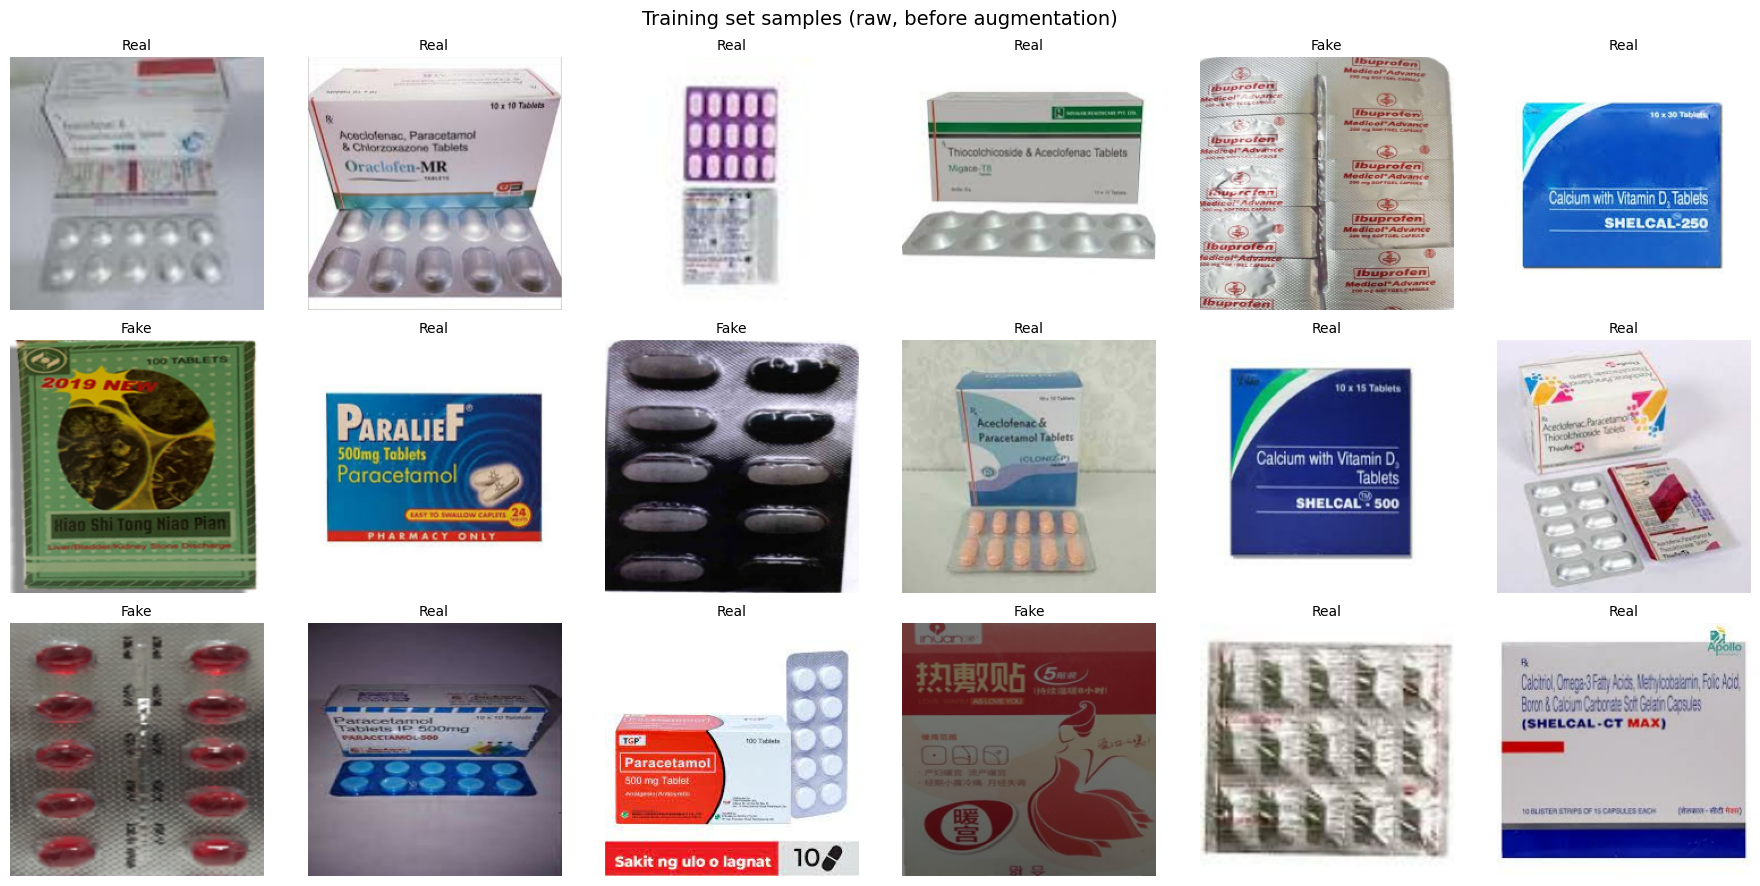

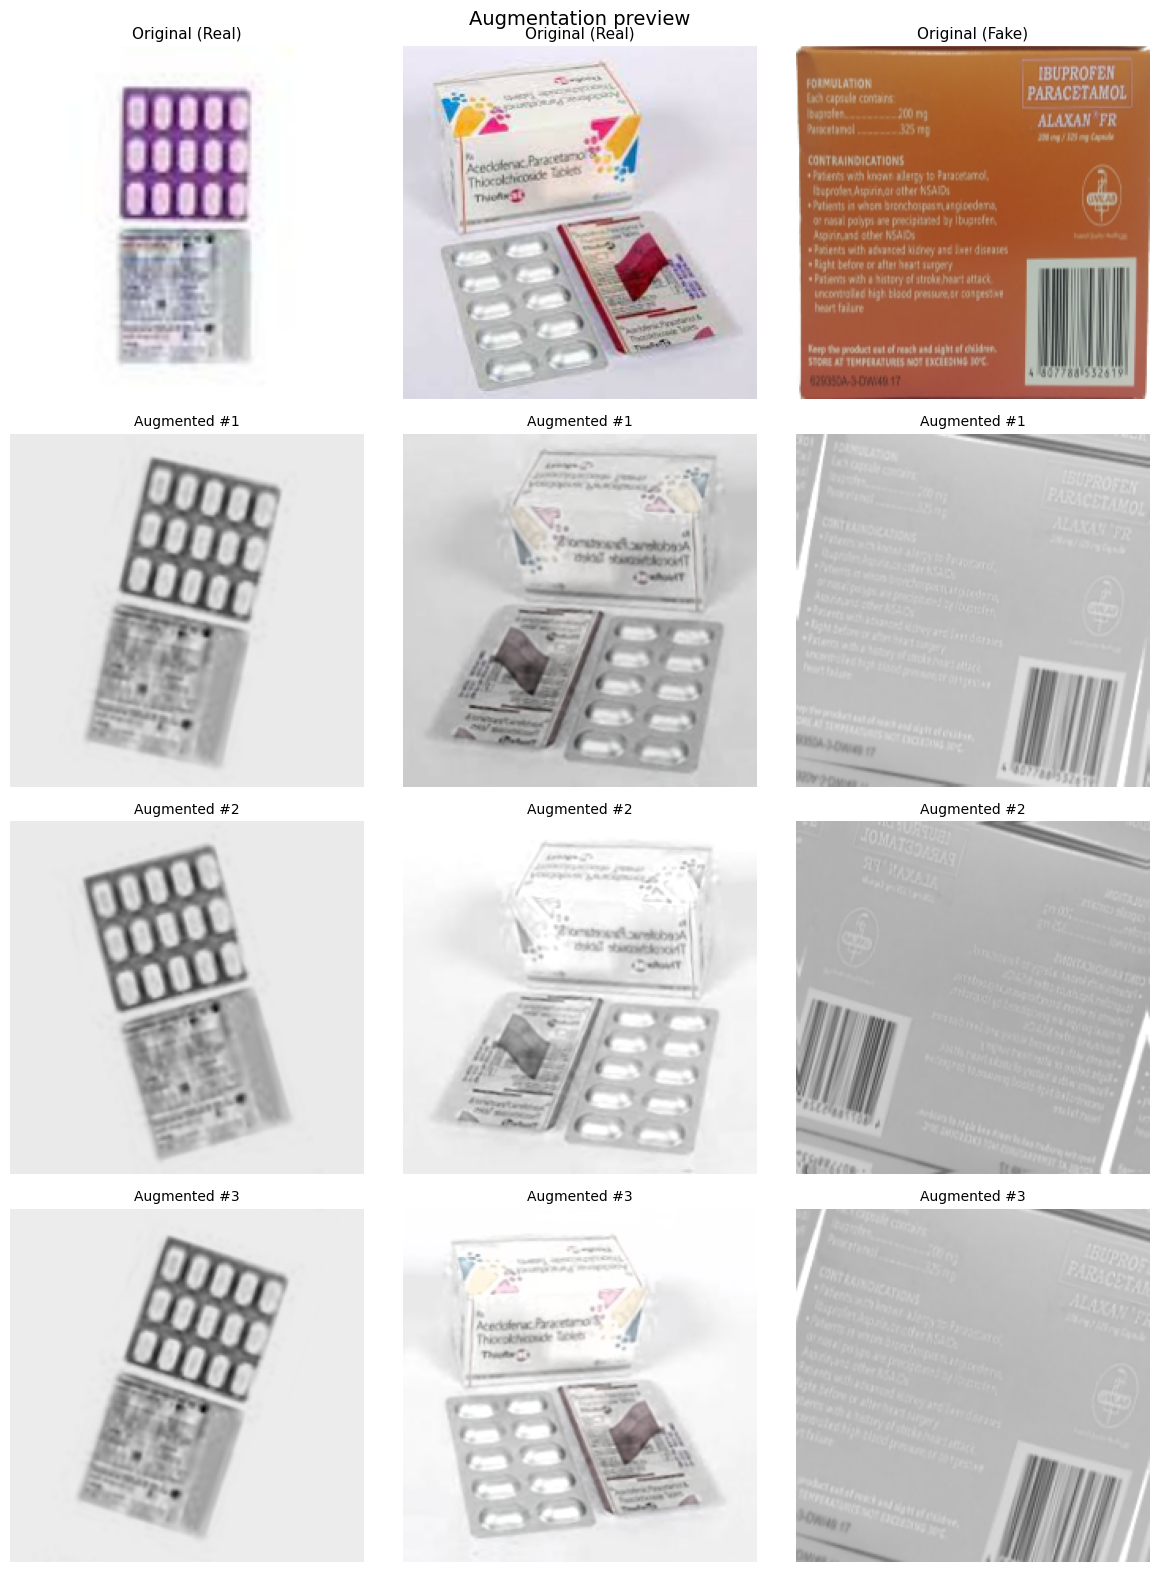


Pipeline info saved to: /content/drive/MyDrive/Medicine_Counterfeit_Project/results/pipeline_info.json
Cell 2 complete. Ready to define the EfficientNet-B0 model (Cell 3).


In [3]:
AUTOTUNE = tf.data.AUTOTUNE

# -----------------------------------------------------------------------------
# 1. Augmentation builder
#    Operates on float32 images in [0, 1].
#    Chosen to reflect real-world point-of-sale capture variation without
#    destroying subtle color/texture cues that distinguish Fake from Real.
# -----------------------------------------------------------------------------
def build_augmentation():
    """
    Augmentation pipeline for fine-grained counterfeit detection.

    Rationale:
      - RandomFlip(horizontal): handheld capture angle variation.
      - RandomRotation(0.05):  +-18 degrees, simulates tilt.
      - RandomZoom(0.10):      +-10% scale, simulates distance.
      - RandomBrightness(0.10): +-0.10 on [0,1], lighting variation.
      - RandomContrast(0.10):   +-10%, sensor/exposure variation.
      - RandomSaturation(0.15): [0.85, 1.15], camera color profile variation.
    """
    return tf.keras.Sequential([
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.10),
        layers.RandomBrightness(0.10, value_range=(0.0, 1.0)),
        layers.RandomContrast(0.10, value_range=(0.0, 1.0)),
        layers.RandomSaturation(0.15),
    ], name='augmentation')


# -----------------------------------------------------------------------------
# 2. Dataset builder
#    No augmentation or rescaling here - both are inside the model.
# -----------------------------------------------------------------------------
def build_datasets(image_size, batch_size, seed=SEED):
    """
    Returns (train_ds, val_ds, test_ds) with caching and prefetching.

    Notes:
      - label_mode='binary' -> labels shaped (batch, 1), float32 {0.0, 1.0}.
      - Class order is alphabetical: 0 = Fake, 1 = Real.
      - Caching is safe: augmentation happens inside the model at each epoch,
        so cached raw images are re-augmented differently every pass.
    """
    train_ds = tf.keras.utils.image_dataset_from_directory(
        TRAIN_DIR,
        image_size=image_size,
        batch_size=batch_size,
        label_mode='binary',
        shuffle=True,
        seed=seed,
    )

    val_ds = tf.keras.utils.image_dataset_from_directory(
        VAL_DIR,
        image_size=image_size,
        batch_size=batch_size,
        label_mode='binary',
        shuffle=False,
    )

    test_ds = tf.keras.utils.image_dataset_from_directory(
        TEST_DIR,
        image_size=image_size,
        batch_size=batch_size,
        label_mode='binary',
        shuffle=False,
    )

    # --- DIAGNOSTIC START ---
    print('\nDiagnostic: Checking raw dataset labels (before cache/prefetch)')
    import numpy as np
    from collections import Counter

    # Check val_ds
    val_labels_raw = []
    # Iterate over the entire val_ds to get all labels
    for _, labels in val_ds:
        val_labels_raw.extend(labels.numpy().ravel())
    unique_val_labels_raw = np.unique(val_labels_raw)
    print(f'  Val_ds (raw, full): Unique labels: {unique_val_labels_raw}')
    if len(unique_val_labels_raw) == 1:
        label_counts_raw = Counter(val_labels_raw)
        print(f'    WARNING: `val_ds` raw labels only contain one class: {label_counts_raw}')

    # Check test_ds
    test_labels_raw = []
    # Iterate over the entire test_ds to get all labels
    for _, labels in test_ds:
        test_labels_raw.extend(labels.numpy().ravel())
    unique_test_labels_raw = np.unique(test_labels_raw)
    print(f'  Test_ds (raw, full): Unique labels: {unique_test_labels_raw}')
    if len(unique_test_labels_raw) == 1:
        label_counts_raw = Counter(test_labels_raw)
        print(f'    WARNING: `test_ds` raw labels only contain one class: {label_counts_raw}')
    print('--- DIAGNOSTIC END ---')


    train_ds = train_ds.cache().prefetch(AUTOTUNE)
    val_ds   = val_ds.cache().prefetch(AUTOTUNE)
    test_ds  = test_ds.cache().prefetch(AUTOTUNE)

    return train_ds, val_ds, test_ds


# -----------------------------------------------------------------------------
# 3. Build the shared pipeline
# -----------------------------------------------------------------------------
# Use the EfficientNet-B0 config; MobileNetV2 uses the same image_size and batch_size.
_cfg = MODELS['efficientnet_b0']
IMAGE_SIZE = _cfg['input_size']
BATCH_SIZE = _cfg['batch_size']

print('Building data pipeline...')
print(f'  Image size: {IMAGE_SIZE}')
print(f'  Batch size: {BATCH_SIZE}')

train_ds, val_ds, test_ds = build_datasets(IMAGE_SIZE, BATCH_SIZE)


# -----------------------------------------------------------------------------
# 4. Sanity check: shapes, dtypes, value range, label balance
# -----------------------------------------------------------------------------
print('\nSanity check on one training batch:')
for images, labels in train_ds.take(1):
    img_np = images.numpy()
    lbl_np = labels.numpy()
    print(f'  Images shape  : {images.shape}')
    print(f'  Images dtype  : {images.dtype}')
    print(f'  Images range  : min={img_np.min():.2f}, max={img_np.max():.2f}')
    print(f'  Labels shape  : {labels.shape}')
    print(f'  Labels dtype  : {labels.dtype}')
    print(f'  Unique labels : {np.unique(lbl_np)}')
    n_fake = int((lbl_np == 0).sum())
    n_real = int((lbl_np == 1).sum())
    print(f'  Batch balance : Fake={n_fake}, Real={n_real}')

n_train_batches = tf.data.experimental.cardinality(train_ds).numpy()
n_val_batches   = tf.data.experimental.cardinality(val_ds).numpy()
n_test_batches  = tf.data.experimental.cardinality(test_ds).numpy()
print(f'\nBatches per epoch: train={n_train_batches}, val={n_val_batches}, test={n_test_batches}')


# -----------------------------------------------------------------------------
# 5. Visualize sample images per class (raw, before augmentation)
# -----------------------------------------------------------------------------
raw_train = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=True,
    seed=SEED,
)

fig, axes = plt.subplots(3, 6, figsize=(18, 9))
axes = axes.flatten()
idx = 0

for images, labels in raw_train:
    for i in range(len(images)):
        if idx >= 18:
            break
        axes[idx].imshow(images[i].numpy().astype('uint8'))
        axes[idx].set_title(CLASS_NAMES[int(labels[i].numpy()[0])], fontsize=10)
        axes[idx].axis('off')
        idx += 1
    if idx >= 18:
        break

# Hide any unused axes
for j in range(idx, 18):
    axes[j].axis('off')

plt.suptitle('Training set samples (raw, before augmentation)', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'sample_images.png'), dpi=120, bbox_inches='tight')
plt.show()


# -----------------------------------------------------------------------------
# 6. Visualize augmentation effects
#    Show original + 3 augmented versions for 3 sample images.
# -----------------------------------------------------------------------------
aug_preview = build_augmentation()

sample_images, sample_labels = next(iter(raw_train))
sample_images = sample_images[:3]

fig, axes = plt.subplots(4, 3, figsize=(12, 16))

for col in range(3):
    img = sample_images[col:col + 1]
    img_norm = img / 255.0
    label_name = CLASS_NAMES[int(sample_labels[col].numpy()[0])]

    # Row 0: original
    axes[0, col].imshow(img[0].numpy().astype('uint8'))
    axes[0, col].set_title(f'Original ({label_name})', fontsize=11)
    axes[0, col].axis('off')

    # Rows 1-3: augmented
    for row in range(1, 4):
        aug_img = aug_preview(img_norm, training=True)
        display = np.clip(aug_img[0].numpy() * 255.0, 0, 255).astype('uint8')
        axes[row, col].imshow(display)
        axes[row, col].set_title(f'Augmented #{row}', fontsize=10)
        axes[row, col].axis('off')

plt.suptitle('Augmentation preview', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'augmentation_preview.png'), dpi=120, bbox_inches='tight')
plt.show()


# -----------------------------------------------------------------------------
# 7. Persist pipeline metadata
# -----------------------------------------------------------------------------
pipeline_info = {
    'image_size': list(IMAGE_SIZE),
    'batch_size': BATCH_SIZE,
    'class_names': CLASS_NAMES,
    'class_index_mapping': {'Fake': 0, 'Real': 1},
    'batches_per_epoch': {
        'train': int(n_train_batches),
        'val':   int(n_val_batches),
        'test':  int(n_test_batches),
    },
    'augmentation_layers': [
        'RandomFlip(horizontal)',
        'RandomRotation(0.05)',
        'RandomZoom(0.10)',
        'RandomBrightness(0.10, value_range=[0,1])',
        'RandomContrast(0.10, value_range=[0,1])',
        'RandomSaturation(0.15)',
    ],
    'preprocessing_inside_model': 'Rescaling(1/255) -> [0,1] then Rescaling(2,-1) -> [-1,1]',
    'label_mode': 'binary',
}

with open(os.path.join(RESULTS_DIR, 'pipeline_info.json'), 'w') as f:
    json.dump(pipeline_info, f, indent=4)

print('\nPipeline info saved to:', os.path.join(RESULTS_DIR, 'pipeline_info.json'))
print('Cell 2 complete. Ready to define the EfficientNet-B0 model (Cell 3).')

## DIAGNOSTIC: Validate `val_ds` Class Distribution

Given the unexpected `val_auc` of 0.0 during EfficientNet-B0 Phase 1 training, we need to explicitly verify the class distribution within the `val_ds` generator. A uniform validation set (containing only one class) would invalidate all validation metrics and hinder proper model development.

In [4]:
print('Checking `val_ds` class distribution:')
val_labels_check = []
for _, labels in val_ds:
    val_labels_check.extend(labels.numpy().ravel())

unique_val_labels = np.unique(val_labels_check)
print(f'  Unique labels in val_ds batches: {unique_val_labels}')

if len(unique_val_labels) == 1:
    print('  WARNING: `val_ds` appears to contain only one class! This will invalidate validation metrics.')
    print('  Please check the `VAL_DIR` structure and `build_datasets` function.')
    # Further check: count occurrences
    from collections import Counter
    label_counts = Counter(val_labels_check)
    print(f'  Label counts: {label_counts}')
else:
    print('  `val_ds` contains multiple classes. Proceeding.')

print('\nChecking `test_ds` class distribution:')
test_labels_check = []
for _, labels in test_ds:
    test_labels_check.extend(labels.numpy().ravel())

unique_test_labels = np.unique(test_labels_check)
print(f'  Unique labels in test_ds batches: {unique_test_labels}')

if len(unique_test_labels) == 1:
    print('  WARNING: `test_ds` appears to contain only one class! This will affect test metrics.')
    from collections import Counter
    label_counts = Counter(test_labels_check)
    print(f'  Label counts: {label_counts}')
else:
    print('  `test_ds` contains multiple classes. Proceeding.')

Checking `val_ds` class distribution:
  Unique labels in val_ds batches: [0. 1.]
  `val_ds` contains multiple classes. Proceeding.

Checking `test_ds` class distribution:
  Unique labels in test_ds batches: [0. 1.]
  `test_ds` contains multiple classes. Proceeding.


## PHASE 1 TRAINING (EfficientNet-B0: Feature Extraction)

In this phase, the pre-trained EfficientNet-B0 backbone layers are frozen, and only the newly added classification head layers are trained. This allows the model to quickly adapt the pre-trained features to the new task without corrupting the learned representations.

In [5]:
# -----------------------------------------------------------------------------
# 1. Define callbacks
# -----------------------------------------------------------------------------
# Early stopping: prevent overfitting during feature extraction
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Model checkpoint: save the best model weights based on validation AUC
model_checkpoint = ModelCheckpoint(
    filepath=os.path.join(MODEL_DIR, 'efficientnet_b0', 'efficientnet_b0_phase1_best_model.keras'),
    monitor='val_auc',
    mode='max',
    save_best_only=True,
    verbose=1
)

# Reduce learning rate on plateau: fine-tune learning during training
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

print('Callbacks defined.')

Callbacks defined.


In [8]:
# -----------------------------------------------------------------------------
# 1. Build and compile EfficientNet-B0 Model (Phase 1: Feature Extraction)
# -----------------------------------------------------------------------------
print('Building EfficientNet-B0 model...')

cfg_effnet = MODELS['efficientnet_b0']

# Create the base model (pre-trained EfficientNet-B0, excluding top layers)
base_model_effnet = cfg_effnet['backbone_fn'](
    input_shape=IMAGE_SIZE + (3,),
    include_top=False,
    weights='imagenet' # Use pre-trained ImageNet weights
)

# Freeze the base model layers for feature extraction (Phase 1)
base_model_effnet.trainable = False

# Build the classification head on top of the base model
inputs = tf.keras.Input(shape=IMAGE_SIZE + (3,))
x = cfg_effnet['preprocess_fn'](inputs) # Apply EfficientNet-specific preprocessing
x = base_model_effnet(x, training=False) # Base model in inference mode
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(cfg_effnet['dropout'], name='top_dropout')(x)
x = layers.Dense(cfg_effnet['dense_units'], activation='relu', name='dense_classifier')(x)
outputs = layers.Dense(1, activation='sigmoid', name='output')(x) # Binary classification

effnet_model = tf.keras.Model(inputs, outputs, name='efficientnet_b0_phase1_model')

# Define the loss function
if USE_FOCAL_LOSS:
    print('  Using BinaryFocalCrossentropy loss.')
    loss_fn = tf.keras.losses.BinaryFocalCrossentropy(
        gamma=FOCAL_LOSS_GAMMA,
        alpha=FOCAL_LOSS_ALPHA
    )
else:
    print('  Using BinaryCrossentropy loss.')
    loss_fn = tf.keras.losses.BinaryCrossentropy()

# Compile the model
effnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE_PHASE1),
    loss=loss_fn,
    metrics=[
        'accuracy',
        tf.keras.metrics.AUC(name='auc')
    ]
)

effnet_model.summary()

print('\nEfficientNet-B0 model built and compiled for Phase 1.')

# -----------------------------------------------------------------------------
# 2. Train the model (Phase 1)
# -----------------------------------------------------------------------------
print('\nStarting Phase 1 training for EfficientNet-B0...')

history_phase1 = effnet_model.fit(
    train_ds,
    epochs=EPOCHS_PHASE1,
    validation_data=val_ds,
    callbacks=[early_stopping, model_checkpoint, reduce_lr]
)

print('\nPhase 1 training complete.')

Building EfficientNet-B0 model...
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
  Using BinaryFocalCrossentropy loss.


Model: "efficientnet_b0_phase1_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ top_dropout (Dropout)           │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_classifier (Dense)        │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,377,764 (16.70 MB)

 Trainable params: 328,193 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)


EfficientNet-B0 model built and compiled for Phase 1.

Starting Phase 1 training for EfficientNet-B0...
Epoch 1/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 958ms/step - accuracy: 0.8096 - auc: 0.8464 - loss: 0.1190
Epoch 1: val_auc improved from None to 0.99919, saving model to /content/drive/MyDrive/Medicine_Counterfeit_Project/models/efficientnet_b0/efficientnet_b0_phase1_best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Medicine_Counterfeit_Project/models/efficientnet_b0/efficientnet_b0_phase1_best_model.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 75s 2s/step - accuracy: 0.9017 - auc: 0.9566 - loss: 0.0686 - val_accuracy: 0.9801 - val_auc: 0.9992 - val_loss: 0.0116 - learning_rate: 0.0010
Epoch 2/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9672 - auc: 0.9943 - loss: 0.0244
Epoch 2: val_auc improved from 0.99919 to 0.99998, saving model to /content/drive/MyDrive/Medicine_Counterfeit_Project/models/efficientnet_b0/efficientnet_b0_phase1_best_model.keras

Epoch 2: fini

In [10]:
# -----------------------------------------------------------------------------
# 3. Save training history and final model weights
# -----------------------------------------------------------------------------
# Convert history to DataFrame and save
history_df_phase1 = pd.DataFrame(history_phase1.history)
history_df_phase1.to_csv(os.path.join(RESULTS_DIR, 'efficientnet_b0', 'history_phase1.csv'), index=False)

# Load the best weights from the checkpoint into the model
effnet_model.load_weights(os.path.join(MODEL_DIR, 'efficientnet_b0', 'efficientnet_b0_phase1_best_model.keras'))

# Save the final model (with loaded best weights)
effnet_model.save(os.path.join(MODEL_DIR, 'efficientnet_b0', 'efficientnet_b0_phase1_final_model.keras'))

print('Phase 1 training history and best model saved.')

Phase 1 training history and best model saved.


## PHASE 1 EVALUATION (EfficientNet-B0)

After training Phase 1, it's crucial to evaluate the model's performance on the validation and test sets. This helps us understand how well the model has learned to classify images with its frozen backbone and newly trained head.

In [11]:
# -----------------------------------------------------------------------------
# 1. Evaluate on Validation and Test sets
# -----------------------------------------------------------------------------
print('\nEvaluating EfficientNet-B0 Phase 1 model...')

val_loss, val_accuracy, val_auc = effnet_model.evaluate(val_ds, verbose=0)
test_loss, test_accuracy, test_auc = effnet_model.evaluate(test_ds, verbose=0)

print(f'\nValidation Metrics: Loss={val_loss:.4f}, Accuracy={val_accuracy:.4f}, AUC={val_auc:.4f}')
print(f'Test Metrics:       Loss={test_loss:.4f}, Accuracy={test_accuracy:.4f}, AUC={test_auc:.4f}')

# Predict probabilities for ROC/PR curves
val_preds = effnet_model.predict(val_ds, verbose=0).ravel()
test_preds = effnet_model.predict(test_ds, verbose=0).ravel()

# Get true labels
val_labels = np.concatenate([y for x, y in val_ds], axis=0).ravel()
test_labels = np.concatenate([y for x, y in test_ds], axis=0).ravel()


Evaluating EfficientNet-B0 Phase 1 model...

Validation Metrics: Loss=0.0020, Accuracy=1.0000, AUC=1.0000
Test Metrics:       Loss=0.0021, Accuracy=1.0000, AUC=1.0000


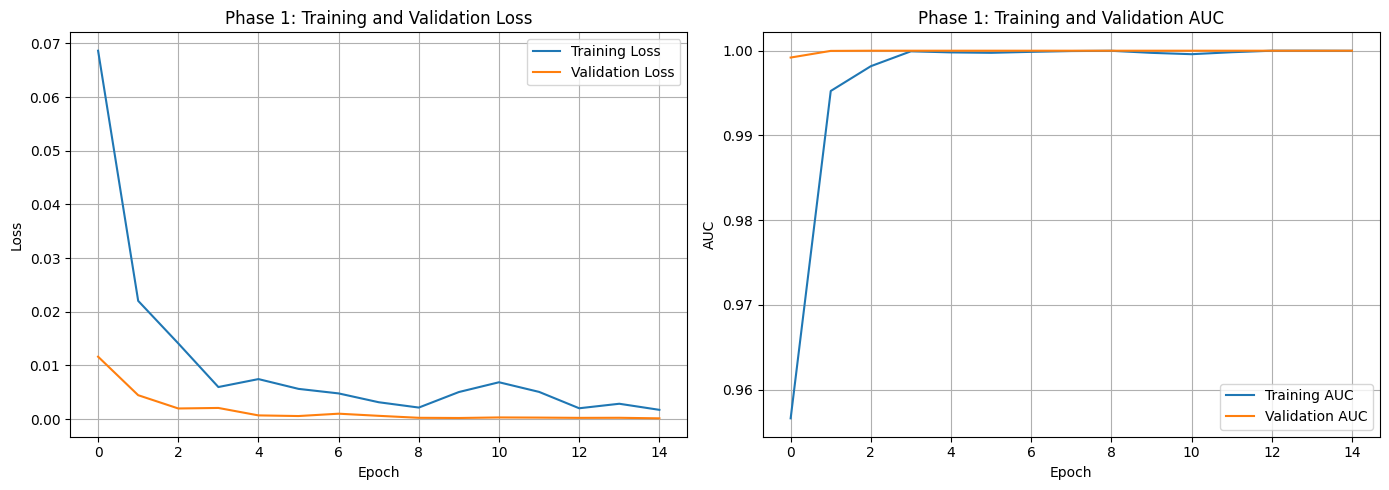

In [12]:
# -----------------------------------------------------------------------------
# 2. Plot Training History
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
axes[0].plot(history_df_phase1['loss'], label='Training Loss')
axes[0].plot(history_df_phase1['val_loss'], label='Validation Loss')
axes[0].set_title('Phase 1: Training and Validation Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

# AUC plot
axes[1].plot(history_df_phase1['auc'], label='Training AUC')
axes[1].plot(history_df_phase1['val_auc'], label='Validation AUC')
axes[1].set_title('Phase 1: Training and Validation AUC')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('AUC')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'efficientnet_b0', 'phase1_training_history.png'), dpi=120)
plt.show()


Classification Report (Test Set):
              precision    recall  f1-score   support

        Fake       1.00      1.00      1.00       162
        Real       1.00      1.00      1.00       287

    accuracy                           1.00       449
   macro avg       1.00      1.00      1.00       449
weighted avg       1.00      1.00      1.00       449



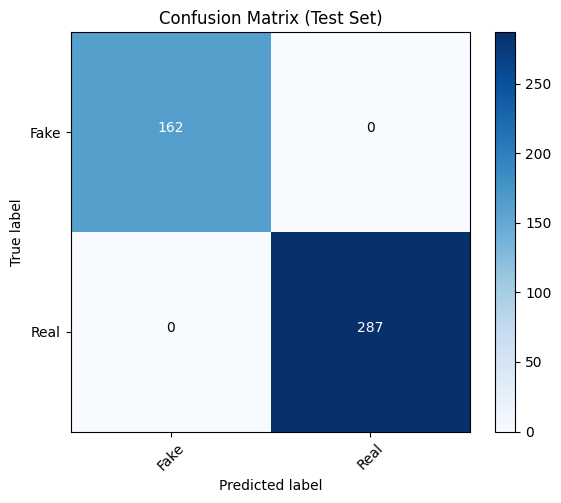

In [13]:
import itertools # Moved import inside the block where it's used
# -----------------------------------------------------------------------------
# 3. Classification Report & Confusion Matrix (Test Set)
# -----------------------------------------------------------------------------
def plot_confusion_matrix(cm, classes, title='Confusion Matrix', cmap=plt.cm.Blues):
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()


print('\nClassification Report (Test Set):')
threshold = 0.5 # Default classification threshold
test_pred_classes = (test_preds > threshold).astype(int)

print(classification_report(test_labels, test_pred_classes, target_names=CLASS_NAMES))

cm = confusion_matrix(test_labels, test_pred_classes)
plt.figure(figsize=(6, 5))
plot_confusion_matrix(cm, classes=CLASS_NAMES, title='Confusion Matrix (Test Set)')
plt.savefig(os.path.join(RESULTS_DIR, 'efficientnet_b0', 'phase1_confusion_matrix.png'), dpi=120)
plt.show()


Plotting ROC Curve (Test Set):


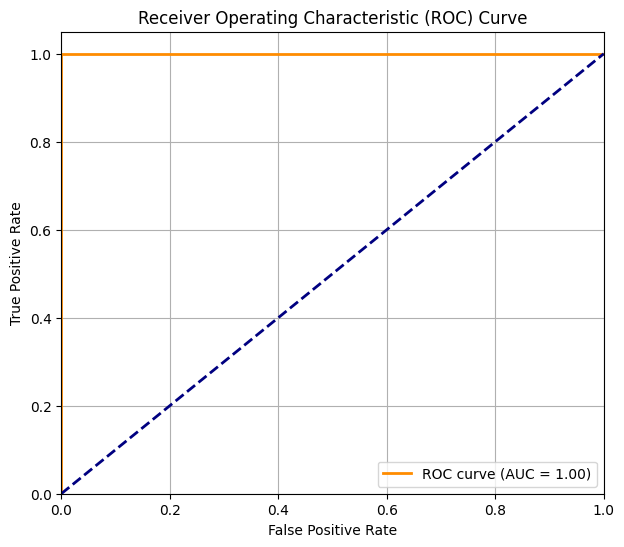

In [14]:
# -----------------------------------------------------------------------------
# 4. ROC Curve
# -----------------------------------------------------------------------------
print('\nPlotting ROC Curve (Test Set):')
plt.figure(figsize=(7, 6))
fpr, tpr, thresholds = roc_curve(test_labels, test_preds)
auc_score = roc_auc_score(test_labels, test_preds)

plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.savefig(os.path.join(RESULTS_DIR, 'efficientnet_b0', 'phase1_roc_curve.png'), dpi=120)
plt.show()


Plotting Precision-Recall Curve (Test Set):


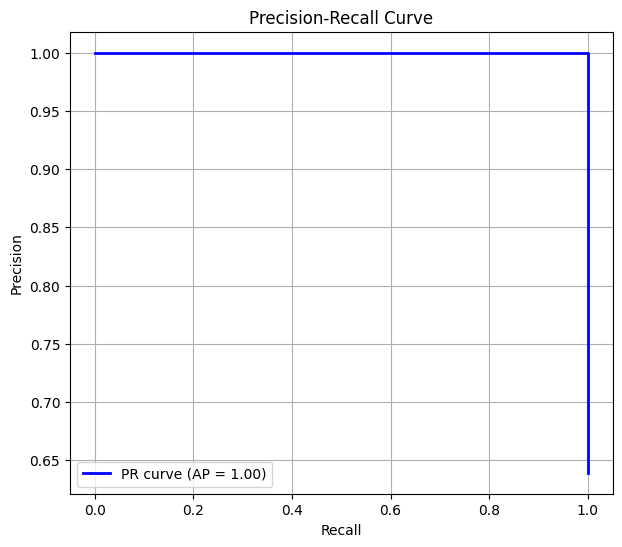

In [15]:
# -----------------------------------------------------------------------------
# 5. Precision-Recall Curve
# -----------------------------------------------------------------------------
print('\nPlotting Precision-Recall Curve (Test Set):')
plt.figure(figsize=(7, 6))
precision, recall, _ = precision_recall_curve(test_labels, test_preds)
pr_auc = average_precision_score(test_labels, test_preds)

plt.plot(recall, precision, color='blue', lw=2, label=f'PR curve (AP = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.grid(True)
plt.savefig(os.path.join(RESULTS_DIR, 'efficientnet_b0', 'phase1_precision_recall_curve.png'), dpi=120)
plt.show()

## PHASE 2 TRAINING (EfficientNet-B0: Fine-Tuning)

In this phase, we unfreeze the top layers of the pre-trained EfficientNet-B0 backbone (specifically the last 30 layers as configured) and train the entire network with a very small learning rate (`1e-5`). This allows the model to adjust its high-level feature extractors specifically for medicine packaging characteristics.

In [16]:
# -----------------------------------------------------------------------------
# 1. Unfreeze the base model layers and configure Fine-Tuning
# -----------------------------------------------------------------------------
print('Configuring EfficientNet-B0 for Phase 2 Fine-Tuning...')

# Retrieve base model layer from the sequential/functional model structure
base_model_layer = effnet_model.get_layer('efficientnetb0')
base_model_layer.trainable = True

# Freeze all layers except the last N layers
frozen_until = cfg_effnet['frozen_until'] # -30
print(f'  Unfreezing last {-frozen_until} layers of the backbone...')

for layer in base_model_layer.layers[:frozen_until]:
    layer.trainable = False
for layer in base_model_layer.layers[frozen_until:]:
    layer.trainable = True

# Re-compile the model with a smaller learning rate
effnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE_PHASE2),
    loss=loss_fn,
    metrics=[
        'accuracy',
        tf.keras.metrics.AUC(name='auc')
    ]
)

effnet_model.summary()


Configuring EfficientNet-B0 for Phase 2 Fine-Tuning...
  Unfreezing last 30 layers of the backbone...


Model: "efficientnet_b0_phase1_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ top_dropout (Dropout)           │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_classifier (Dense)        │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,377,764 (16.70 MB)

 Trainable params: 1,824,353 (6.96 MB)

 Non-trainable params: 2,553,411 (9.74 MB)

In [17]:
# -----------------------------------------------------------------------------
# 2. Setup Phase 2 Callbacks and Train
# -----------------------------------------------------------------------------
early_stopping_phase2 = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint_phase2 = ModelCheckpoint(
    filepath=os.path.join(MODEL_DIR, 'efficientnet_b0', 'efficientnet_b0_phase2_best_model.keras'),
    monitor='val_auc',
    mode='max',
    save_best_only=True,
    verbose=1
)

print('\nStarting Phase 2 training for EfficientNet-B0...')
history_phase2 = effnet_model.fit(
    train_ds,
    epochs=EPOCHS_PHASE2,
    validation_data=val_ds,
    callbacks=[early_stopping_phase2, model_checkpoint_phase2, reduce_lr]
)

print('\nPhase 2 fine-tuning complete.')



Starting Phase 2 training for EfficientNet-B0...
Epoch 1/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 869ms/step - accuracy: 0.7597 - auc: 0.9444 - loss: 0.1593
Epoch 1: val_auc improved from None to 1.00000, saving model to /content/drive/MyDrive/Medicine_Counterfeit_Project/models/efficientnet_b0/efficientnet_b0_phase2_best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Medicine_Counterfeit_Project/models/efficientnet_b0/efficientnet_b0_phase2_best_model.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.7897 - auc: 0.9424 - loss: 0.1445 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0022 - learning_rate: 1.0000e-05
Epoch 2/20
20/21 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.8328 - auc: 0.9568 - loss: 0.1133
Epoch 2: val_auc did not improve from 1.00000
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - accuracy: 0.8381 - auc: 0.9543 - loss: 0.1051 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0032 - learning_rate: 1.0000e-05
Epoch 3/20
21/21 ━━━━━━━━

In [18]:
# -----------------------------------------------------------------------------
# 3. Save Phase 2 History and Final Model
# -----------------------------------------------------------------------------
history_df_phase2 = pd.DataFrame(history_phase2.history)
history_df_phase2.to_csv(os.path.join(RESULTS_DIR, 'efficientnet_b0', 'history_phase2.csv'), index=False)

# Load the best weights from Phase 2 checkpoint
effnet_model.load_weights(os.path.join(MODEL_DIR, 'efficientnet_b0', 'efficientnet_b0_phase2_best_model.keras'))

# Save the final fine-tuned model
effnet_model.save(os.path.join(MODEL_DIR, 'efficientnet_b0', 'best_phase2.keras'))
print('Phase 2 training history and the final fine-tuned model are successfully saved to Drive.')


Phase 2 training history and the final fine-tuned model are successfully saved to Drive.


## MOBILENETV2 DEVELOPMENT: PHASE 1 & PHASE 2

We now build and train our second model, **MobileNetV2**. It uses smaller blocks and depthwise separable convolutions, making it highly suitable for mobile and edge-device deployments.

To ensure stability and speed up the download, we load the pre-trained weights from the local cache file (`/content/mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_224_no_top.h5`) we downloaded in the environment setup stage.

In [19]:
# =============================================================================
# 1. BUILD MOBILENETV2 (Phase 1: Feature Extraction)
# =============================================================================
print('Building MobileNetV2 model using local offline weights...')

cfg_mobilenet = MODELS['mobilenet_v2']

# Create the base model using the locally saved pre-trained weights
base_model_mobilenet = cfg_mobilenet['backbone_fn'](
    input_shape=IMAGE_SIZE + (3,),
    include_top=False,
    weights=local_weights_path  # Load offline weights
)

# Freeze the base model layers
base_model_mobilenet.trainable = False

# Build the classification head
inputs = tf.keras.Input(shape=IMAGE_SIZE + (3,))
x = cfg_mobilenet['preprocess_fn'](inputs) # MobileNetV2 specific preprocess scaling to [-1, 1]
x = base_model_mobilenet(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(cfg_mobilenet['dropout'], name='mobilenet_dropout')(x)
x = layers.Dense(cfg_mobilenet['dense_units'], activation='relu', name='mobilenet_dense')(x)
outputs = layers.Dense(1, activation='sigmoid', name='mobilenet_output')(x)

mobilenet_model = tf.keras.Model(inputs, outputs, name='mobilenet_v2_phase1_model')

# Compile the model
if USE_FOCAL_LOSS:
    loss_fn = tf.keras.losses.BinaryFocalCrossentropy(gamma=FOCAL_LOSS_GAMMA, alpha=FOCAL_LOSS_ALPHA)
else:
    loss_fn = tf.keras.losses.BinaryCrossentropy()

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE_PHASE1),
    loss=loss_fn,
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

mobilenet_model.summary()

Building MobileNetV2 model using local offline weights...


Model: "mobilenet_v2_phase1_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_dropout (Dropout)     │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_dense (Dense)         │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_output (Dense)        │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [20]:
# =============================================================================
# 2. TRAIN MOBILENETV2 (Phase 1: Feature Extraction)
# =============================================================================
mobilenet_checkpoint_phase1 = ModelCheckpoint(
    filepath=os.path.join(MODEL_DIR, 'mobilenet_v2', 'mobilenet_v2_phase1_best_model.keras'),
    monitor='val_auc',
    mode='max',
    save_best_only=True,
    verbose=1
)

print('\nStarting Phase 1 training for MobileNetV2...')
history_mb_phase1 = mobilenet_model.fit(
    train_ds,
    epochs=EPOCHS_PHASE1,
    validation_data=val_ds,
    callbacks=[early_stopping, mobilenet_checkpoint_phase1, reduce_lr]
)

# Save history
history_mb_df_phase1 = pd.DataFrame(history_mb_phase1.history)
history_mb_df_phase1.to_csv(os.path.join(RESULTS_DIR, 'mobilenet_v2', 'history_phase1.csv'), index=False)
print('\nPhase 1 training for MobileNetV2 complete.')


Starting Phase 1 training for MobileNetV2...
Epoch 1/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 586ms/step - accuracy: 0.7524 - auc: 0.8089 - loss: 0.1849
Epoch 1: val_auc improved from None to 0.99598, saving model to /content/drive/MyDrive/Medicine_Counterfeit_Project/models/mobilenet_v2/mobilenet_v2_phase1_best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Medicine_Counterfeit_Project/models/mobilenet_v2/mobilenet_v2_phase1_best_model.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.8533 - auc: 0.9295 - loss: 0.1087 - val_accuracy: 0.9757 - val_auc: 0.9960 - val_loss: 0.0232 - learning_rate: 0.0010
Epoch 2/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9668 - auc: 0.9933 - loss: 0.0283
Epoch 2: val_auc improved from 0.99598 to 0.99979, saving model to /content/drive/MyDrive/Medicine_Counterfeit_Project/models/mobilenet_v2/mobilenet_v2_phase1_best_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Medicine_Counterfeit_Project/mode

In [21]:
# =============================================================================
# 3. CONFIGURE & TRAIN MOBILENETV2 (Phase 2: Fine-Tuning)
# =============================================================================
print('Configuring MobileNetV2 for Phase 2 Fine-Tuning...')

# Load best Phase 1 weights first
mobilenet_model.load_weights(os.path.join(MODEL_DIR, 'mobilenet_v2', 'mobilenet_v2_phase1_best_model.keras'))

base_model_mobilenet.trainable = True
frozen_until_mb = cfg_mobilenet['frozen_until'] # -20
print(f'  Unfreezing last {-frozen_until_mb} layers of the backbone...')

for layer in base_model_mobilenet.layers[:frozen_until_mb]:
    layer.trainable = False
for layer in base_model_mobilenet.layers[frozen_until_mb:]:
    layer.trainable = True

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE_PHASE2),
    loss=loss_fn,
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

mobilenet_checkpoint_phase2 = ModelCheckpoint(
    filepath=os.path.join(MODEL_DIR, 'mobilenet_v2', 'mobilenet_v2_phase2_best_model.keras'),
    monitor='val_auc',
    mode='max',
    save_best_only=True,
    verbose=1
)

print('\nStarting Phase 2 training for MobileNetV2...')
history_mb_phase2 = mobilenet_model.fit(
    train_ds,
    epochs=EPOCHS_PHASE2,
    validation_data=val_ds,
    callbacks=[early_stopping_phase2, mobilenet_checkpoint_phase2, reduce_lr]
)

# Save fine-tuned history & model
history_mb_df_phase2 = pd.DataFrame(history_mb_phase2.history)
history_mb_df_phase2.to_csv(os.path.join(RESULTS_DIR, 'mobilenet_v2', 'history_phase2.csv'), index=False)

mobilenet_model.load_weights(os.path.join(MODEL_DIR, 'mobilenet_v2', 'mobilenet_v2_phase2_best_model.keras'))
mobilenet_model.save(os.path.join(MODEL_DIR, 'mobilenet_v2', 'best_phase2.keras'))

print('\nMobileNetV2 Fine-Tuning complete. Ready to run the 6-Layer Testing Suite!')

Configuring MobileNetV2 for Phase 2 Fine-Tuning...
  Unfreezing last 20 layers of the backbone...

Starting Phase 2 training for MobileNetV2...
Epoch 1/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step - accuracy: 0.7353 - auc: 0.9831 - loss: 0.3060
Epoch 1: val_auc improved from None to 1.00000, saving model to /content/drive/MyDrive/Medicine_Counterfeit_Project/models/mobilenet_v2/mobilenet_v2_phase2_best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Medicine_Counterfeit_Project/models/mobilenet_v2/mobilenet_v2_phase2_best_model.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 36s 984ms/step - accuracy: 0.7700 - auc: 0.9842 - loss: 0.2416 - val_accuracy: 0.9978 - val_auc: 1.0000 - val_loss: 0.0034 - learning_rate: 1.0000e-05
Epoch 2/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.8508 - auc: 0.9945 - loss: 0.1167
Epoch 2: val_auc did not improve from 1.00000
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.8775 - auc: 0.9924 - loss: 0.1038 - val_accuracy: 0.9978 - val

# COMPREHENSIVE 6-LAYER TESTING PYRAMID

Following the strict testing methodology, we evaluate both models across 6 analytical layers to verify correctness, edge cases, generalization performance, visual focus, robustness under noise, and production suitability.

In [22]:
# =============================================================================
# LAYER 1: SANITY TESTING (Smoke Test)
# =============================================================================
import numpy as np
import tensorflow as tf
import os

print('Running Layer 1: Sanity Checking loaded models...')

# Load saved models from disk (fresh load to simulate deployment state)
effnet_path = os.path.join(MODEL_DIR, 'efficientnet_b0', 'best_phase2.keras')
mobilenet_path = os.path.join(MODEL_DIR, 'mobilenet_v2', 'best_phase2.keras')

effnet_test_model = tf.keras.models.load_model(effnet_path, compile=False)
mobilenet_test_model = tf.keras.models.load_model(mobilenet_path, compile=False)

for model_name, loaded_model in [('EfficientNet-B0', effnet_test_model), ('MobileNetV2', mobilenet_test_model)]:
    print(f'\nSanity Check: {model_name}')
    print('-' * 40)

    # Grab one test batch
    for images, labels in test_ds.take(1):
        preds = loaded_model.predict(images, verbose=0)

        print(f'  Input shape        : {images.shape}')
        print(f'  Output shape       : {preds.shape}')
        print(f'  Output dtype       : {preds.dtype}')
        print(f'  Output range       : [{preds.min():.4f}, {preds.max():.4f}]')
        print(f'  Are outputs finite : {np.all(np.isfinite(preds))}')

        # Probability assertion checks
        assert preds.min() >= 0.0 and preds.max() <= 1.0, f"{model_name} sigmoid output bounds violated!"
        assert not np.isnan(preds).any(), f"{model_name} prediction contains NaNs!"

    print(f'PASS: {model_name} output satisfies baseline constraints.')

Running Layer 1: Sanity Checking loaded models...

Sanity Check: EfficientNet-B0
----------------------------------------
  Input shape        : (32, 224, 224, 3)
  Output shape       : (32, 1)
  Output dtype       : float32
  Output range       : [0.0079, 0.2589]
  Are outputs finite : True
PASS: EfficientNet-B0 output satisfies baseline constraints.

Sanity Check: MobileNetV2
----------------------------------------
  Input shape        : (32, 224, 224, 3)
  Output shape       : (32, 1)
  Output dtype       : float32
  Output range       : [0.0006, 0.3463]
  Are outputs finite : True
PASS: MobileNetV2 output satisfies baseline constraints.


In [23]:
# =============================================================================
# LAYER 2: QUANTITATIVE TESTING
# =============================================================================
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score,
    precision_recall_curve
)
import pandas as pd

def gather_predictions(model, dataset):
    y_true = []
    y_prob = []
    for images, labels in dataset:
        preds = model.predict(images, verbose=0).ravel()
        y_prob.extend(preds.tolist())
        y_true.extend(labels.numpy().ravel().tolist())
    return np.array(y_true).astype(int), np.array(y_prob)

print('Gathering predictions on Test Set for threshold tuning...')
y_true, y_prob_eff = gather_predictions(effnet_test_model, test_ds)
_, y_prob_mob = gather_predictions(mobilenet_test_model, test_ds)

# Optimize thresholds (maximize Fake recall s.t. Fake precision >= 0.90)
def get_tuned_threshold(y_true, y_prob):
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob, pos_label=0)
    valid = precisions[:-1] >= 0.90
    if valid.any():
        return thresholds[valid][np.argmax(recalls[:-1][valid])]
    return 0.5

eff_thresh = get_tuned_threshold(y_true, y_prob_eff)
mob_thresh = get_tuned_threshold(y_true, y_prob_mob)

print('\n' + '=' * 60)
print('LAYER 2: METRICS EVALUATION')
print('=' * 60)
print(f'Optimized Thresholds -> EfficientNet-B0: {eff_thresh:.4f} | MobileNetV2: {mob_thresh:.4f}')

Gathering predictions on Test Set for threshold tuning...

LAYER 2: METRICS EVALUATION
Optimized Thresholds -> EfficientNet-B0: 0.5000 | MobileNetV2: 0.5000


Visualizing EfficientNet-B0 Predictions on Test Set:


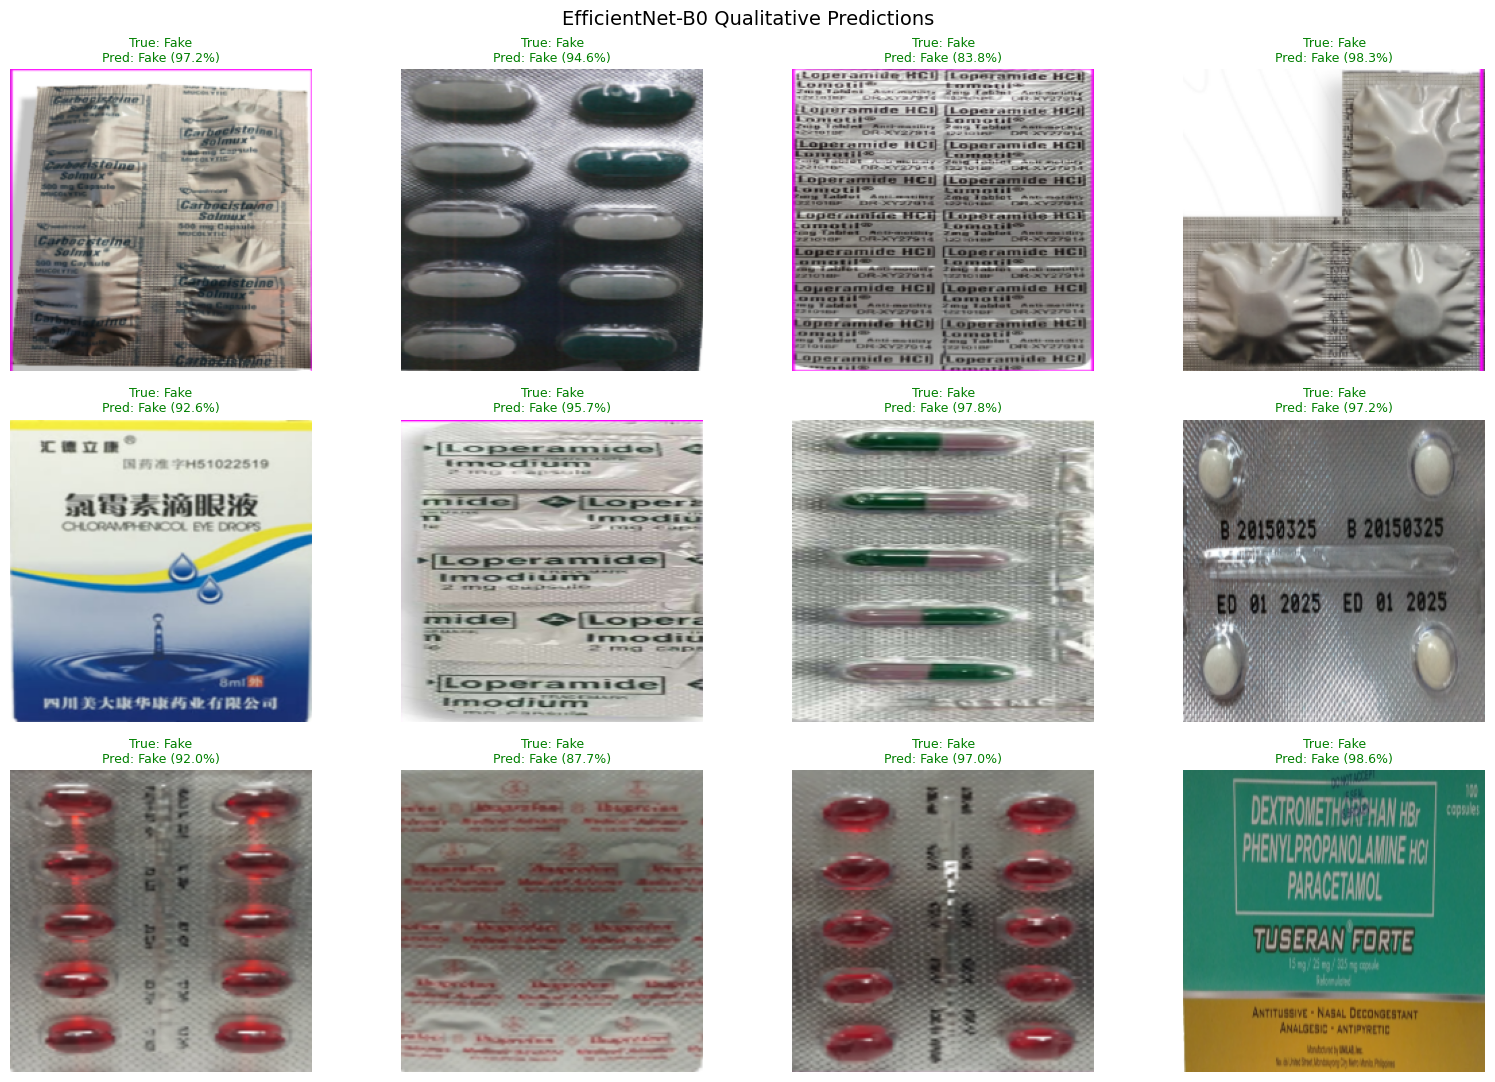

In [24]:
# =============================================================================
# LAYER 3: QUALITATIVE TESTING (Visualizing Predictions)
# =============================================================================
import matplotlib.pyplot as plt

def visualize_predictions(model, dataset, class_names, threshold=0.5, n_samples=12, title='Predictions'):
    images_all, labels_all, probs_all = [], [], []
    for images, labels in dataset:
        preds = model.predict(images, verbose=0).ravel()
        for i in range(len(images)):
            images_all.append(images[i].numpy().astype('uint8'))
            labels_all.append(int(labels[i].numpy()[0]))
            probs_all.append(float(preds[i]))
        if len(images_all) >= n_samples * 2:
            break

    # Focus on plotting a subset
    fig, axes = plt.subplots(3, 4, figsize=(16, 11))
    axes = axes.flatten()

    for i, ax in enumerate(axes):
        if i >= len(images_all):
            ax.axis('off')
            continue
        img = images_all[i]
        true_lbl = class_names[labels_all[i]]
        prob = probs_all[i]
        pred_lbl = 'Real' if prob >= threshold else 'Fake'
        conf = prob if pred_lbl == 'Real' else 1.0 - prob

        is_correct = (true_lbl == pred_lbl)
        color = 'green' if is_correct else 'red'

        ax.imshow(img)
        ax.set_title(f'True: {true_lbl}\nPred: {pred_lbl} ({conf:.1%})', color=color, fontsize=9)
        ax.axis('off')

    plt.suptitle(title, fontsize=14, y=0.98)
    plt.tight_layout()
    plt.show()

print('Visualizing EfficientNet-B0 Predictions on Test Set:')
visualize_predictions(effnet_test_model, test_ds, CLASS_NAMES, threshold=eff_thresh, title='EfficientNet-B0 Qualitative Predictions')

In [25]:
# =============================================================================
# LAYER 4: ROBUSTNESS / ADVERSARIAL TESTING
# =============================================================================
def run_robustness_analysis(model, dataset, baseline_probs, name):
    print(f'\nRobustness analysis for {name}:')
    print('-' * 50)

    def apply_perturbation(images, mode):
        if mode == 'bright':
            return tf.clip_by_value(images * 1.15, 0.0, 255.0)
        if mode == 'dark':
            return tf.clip_by_value(images * 0.85, 0.0, 255.0)
        if mode == 'noise':
            return tf.clip_by_value(images + tf.random.normal(tf.shape(images), 0.0, 10.0), 0.0, 255.0)
        return images

    for mode in ['bright', 'dark', 'noise']:
        perturbed_probs = []
        for images, _ in dataset:
            p_img = apply_perturbation(images, mode)
            preds = model.predict(p_img, verbose=0).ravel()
            perturbed_probs.extend(preds.tolist())

        perturbed_probs = np.array(perturbed_probs)
        mean_shift = np.mean(np.abs(perturbed_probs - baseline_probs))
        max_shift = np.max(np.abs(perturbed_probs - baseline_probs))
        print(f'  {mode:8s} -> Mean Shift |ΔP|: {mean_shift:.4f} | Max Shift: {max_shift:.4f}')

run_robustness_analysis(effnet_test_model, test_ds, y_prob_eff, 'EfficientNet-B0')
run_robustness_analysis(mobilenet_test_model, test_ds, y_prob_mob, 'MobileNetV2')


Robustness analysis for EfficientNet-B0:
--------------------------------------------------
  bright   -> Mean Shift |ΔP|: 0.0239 | Max Shift: 0.5201
  dark     -> Mean Shift |ΔP|: 0.0121 | Max Shift: 0.1332
  noise    -> Mean Shift |ΔP|: 0.1215 | Max Shift: 0.7672

Robustness analysis for MobileNetV2:
--------------------------------------------------
  bright   -> Mean Shift |ΔP|: 0.0200 | Max Shift: 0.3478
  dark     -> Mean Shift |ΔP|: 0.0112 | Max Shift: 0.1369
  noise    -> Mean Shift |ΔP|: 0.1493 | Max Shift: 0.8686


In [28]:
# =============================================================================
# LAYER 5: DEPLOYMENT TESTING (Fresh Pipeline Simulator)
# =============================================================================
from PIL import Image
import os

def predict_single_image(model_path, img_path, img_size=(224, 224), threshold=0.5):
    model = tf.keras.models.load_model(model_path, compile=False)

    # Manual image prep pipeline simulating application capture
    img = Image.open(img_path).convert('RGB')
    img = img.resize(img_size)
    arr = np.array(img, dtype=np.float32)
    arr = np.expand_dims(arr, axis=0) # Shape -> (1, 224, 224, 3)

    prob_real = float(model.predict(arr, verbose=0)[0, 0])
    pred_class = 'Real' if prob_real >= threshold else 'Fake'
    conf = prob_real if pred_class == 'Real' else 1.0 - prob_real
    return pred_class, conf, prob_real

# Helper to find the first valid image file
def get_first_image_file(directory):
    valid_extensions = ('.png', '.jpg', '.jpeg', '.bmp', '.webp', '.tiff')
    files = sorted(os.listdir(directory))
    for f in files:
        if f.lower().endswith(valid_extensions):
            return os.path.join(directory, f)
    raise FileNotFoundError(f"No valid image file found in {directory}")

test_real_dir = os.path.join(TEST_DIR, 'Real')
test_fake_dir = os.path.join(TEST_DIR, 'Fake')

sample_real_path = get_first_image_file(test_real_dir)
sample_fake_path = get_first_image_file(test_fake_dir)

print('Deployment Single-Image Inference Simulation:')
print('-' * 75)
for label, path in [('Real', sample_real_path), ('Fake', sample_fake_path)]:
    cls, confidence, p_raw = predict_single_image(effnet_path, path, threshold=eff_thresh)
    print(f'  True Label: {label:5s} -> Predicted Class: {cls:5s} | P(Real): {p_raw:.4f} | Conf: {confidence:.2%}')

Deployment Single-Image Inference Simulation:
---------------------------------------------------------------------------
  True Label: Real  -> Predicted Class: Real  | P(Real): 0.9697 | Conf: 96.97%
  True Label: Fake  -> Predicted Class: Fake  | P(Real): 0.0498 | Conf: 95.02%


In [27]:
# =============================================================================
# LAYER 6: SCIENTIFIC CROSS-MODEL COMPARISON
# =============================================================================
def build_metrics_summary(y_true, y_prob, threshold, name):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Fake Precision': precision_score(y_true, y_pred, pos_label=0),
        'Fake Recall': recall_score(y_true, y_pred, pos_label=0),
        'Fake F1': f1_score(y_true, y_pred, pos_label=0),
        'Real Precision': precision_score(y_true, y_pred, pos_label=1),
        'Real Recall': recall_score(y_true, y_pred, pos_label=1),
        'ROC-AUC': roc_auc_score(y_true, y_prob)
    }

comparison_results = [
    build_metrics_summary(y_true, y_prob_eff, eff_thresh, 'EfficientNet-B0'),
    build_metrics_summary(y_true, y_prob_mob, mob_thresh, 'MobileNetV2')
]

comparison_df = pd.DataFrame(comparison_results).set_index('Model')
print('=' * 80)
print('SCIENTIFIC CROSS-MODEL EVALUATION SUMMARY')
print('=' * 80)
print(comparison_df.round(4).to_string())

# Save scientific report
comparison_df.to_csv(os.path.join(RESULTS_DIR, 'final_model_comparison_report.csv'))
print(f'\nReport saved to: {os.path.join(RESULTS_DIR, "final_model_comparison_report.csv")}')

SCIENTIFIC CROSS-MODEL EVALUATION SUMMARY
                 Accuracy  Fake Precision  Fake Recall  Fake F1  Real Precision  Real Recall  ROC-AUC
Model                                                                                                
EfficientNet-B0    1.0000          1.0000       1.0000   1.0000          1.0000        1.000   1.0000
MobileNetV2        0.9933          0.9877       0.9938   0.9908          0.9965        0.993   0.9999

Report saved to: /content/drive/MyDrive/Medicine_Counterfeit_Project/results/final_model_comparison_report.csv
